In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%pip install scikit-learn
import scikit-learn as sklearn

  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 2.0 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 1.9 MB/s eta 0:00:04
   ------- -------------------------------- 1.6/8.4 MB 1.8 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.4 MB 2.0 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.4 MB 2.0 MB/s eta 0:00:03
   ------------- -------------------------- 2.9/8.4 MB 2.0 MB/s eta 0:00:03
   ---------------- ----------------------- 3.4/8.4 MB 2.0 MB/s eta 0:00:03
   ------------------ --------------------- 3.9/8.4 MB 2.0 MB/s eta 0:00:03
   -------------------- ------------------- 4.2/8.4 MB 2.0 MB/s eta 0:00:03
   ---------------------- ----------------- 


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
df = pd.read_csv('../data/Advertising.csv')
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [40]:
df.drop(columns=["Unnamed: 0"], inplace=True)

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [43]:
df.isnull().sum()


TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [44]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [46]:
df[['TV', 'Sales']].corr()

,TV,Sales
TV,1.000000,0.782224
Sales,0.782224,1.000000


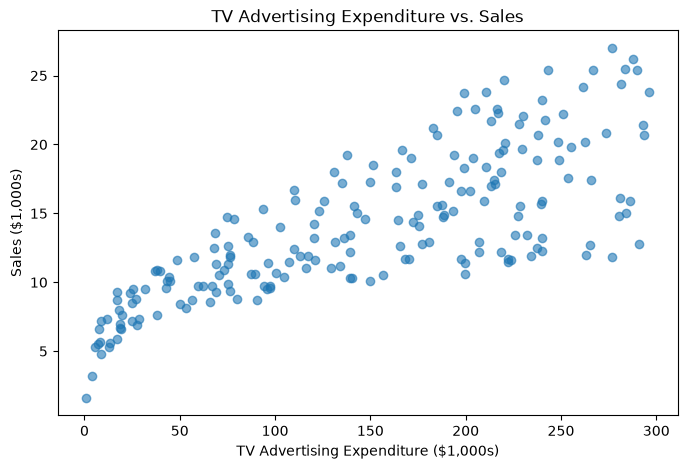

In [47]:

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df['TV'], df['Sales'], alpha=0.6)

# Label the axes
ax.set_xlabel("TV Advertising Expenditure ($1,000s)")
ax.set_ylabel("Sales (Units)")

# Add a title
ax.set_title("TV Advertising Expenditure vs. Sales")

plt.show()

In [48]:

# Feature
X = df[['TV']]

# Target
y = df['Sales']

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (200, 1)
y shape: (200,)


In [52]:
from sklearn.model_selection import train_test_split

# Split X and y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Print the shapes of all four datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (160, 1)
X_test shape: (40, 1)
y_train shape: (160,)
y_test shape: (40,)


In [56]:
import sys
from pathlib import Path

# Get the project root directory
project_root = Path.cwd().parent

# Add the project root to Python's search path
sys.path.insert(0, str(project_root))

# Import the model
from src.linear_regression import SimpleLinearRegression

print("Import successful!")

model = SimpleLinearRegression(
    learning_rate=0.01,
    epochs=2000
)

# TODO1: Train the model using ONLY X_train and y_train
model.fit(X_train, y_train)

#TODO2: Display the learned intercept and slope
print("Learned intercept (theta_0):", model.theta_0)
print("Learned slope (theta_1):", model.theta_1)

##3: Make predictions on X_test
y_pred = model.predict(X_test)

print("\nFirst 5 predictions:")
print(y_pred[:5])

Import successful!
Learned intercept (theta_0): 7.119638417323682
Learned slope (theta_1): 0.04652973361872324

First 5 predictions:
[[14.71794392]
 [16.21154837]
 [20.74819739]
 [ 7.6640363 ]
 [17.37013873]]


In [ ]:
def mean_absolute_error(actual, predicted):
    # Calculate absolute errors
    absolute_errors = np.abs(np.array(actual) - np.array(predicted))

    # Calculate their mean
    mae = np.mean(absolute_errors)

    # Return the result
    return mae


# Test the function
actual = [100, 200, 300]
predicted = [110, 180, 330]

mae = mean_absolute_error(actual, predicted)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 20.0


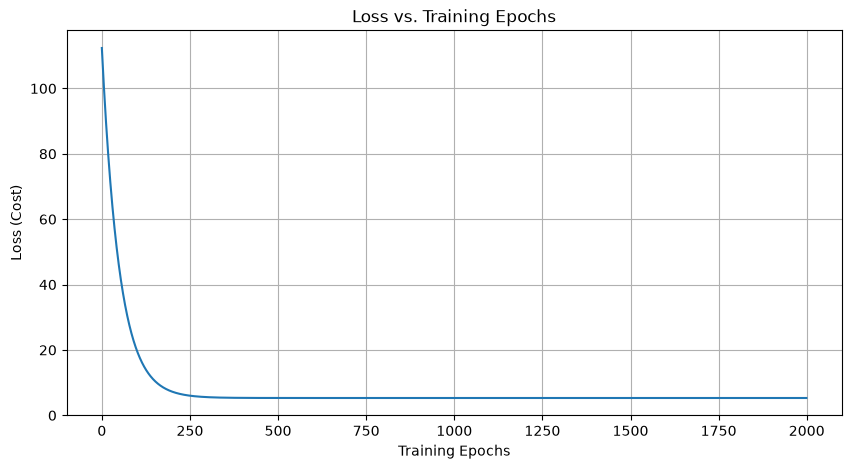

In [59]:
plt.figure(figsize=(10, 5))
plt.plot(model.cost_history)

plt.xlabel("Training Epochs")
plt.ylabel("Loss (Cost)")
plt.title("Loss vs. Training Epochs")
plt.grid(True)

plt.show()

In [62]:
test_mae = mean_absolute_error(y_test, y_pred)

print("Test MAE:", test_mae)


# Build a DataFrame comparing actual and predicted sales
# Compare actual and predicted sales
comparison = pd.DataFrame({
    "Actual Sales": y_test.to_numpy().reshape(-1),
    "Predicted Sales": np.asarray(y_pred).reshape(-1)
})

print(comparison.head(10))

Test MAE: 5.754021516427279
   Actual Sales  Predicted Sales
0          16.9        14.717944
1          22.4        16.211548
2          21.4        20.748197
3           7.3         7.664036
4          24.7        17.370139
5          12.6        10.614021
6          22.3        17.207285
7           8.4         9.446125
8          11.5        17.467851
9          14.9        15.266995


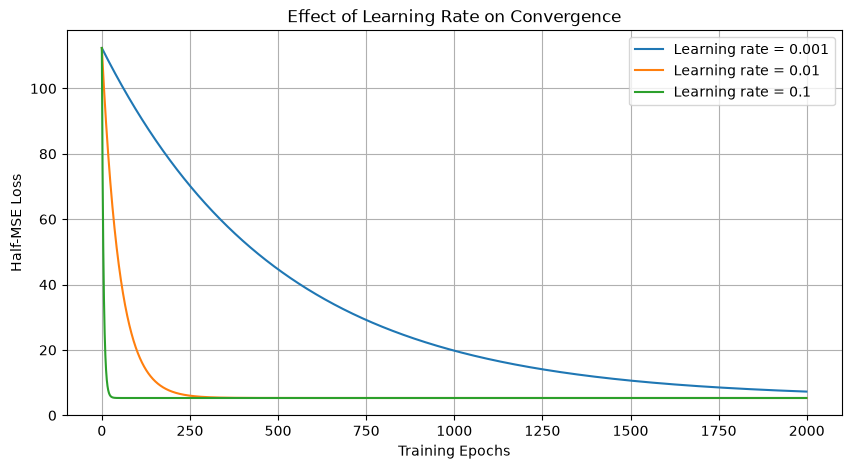

In [63]:

learning_rates = [0.001, 0.01, 0.1]

plt.figure(figsize=(10, 5))

for lr in learning_rates:
    # Create a new model
    model_lr = SimpleLinearRegression(
        learning_rate=lr,
        epochs=2000
    )

    # Train using only the training data
    model_lr.fit(X_train, y_train)

    # Plot the loss history
    plt.plot(
        model_lr.cost_history,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Training Epochs")
plt.ylabel("Half-MSE Loss")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.grid(True)
plt.show()

In [64]:

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

print("Intercept:", model.theta_0)
print("Slope:", model.theta_1)

print("Test MAE:", mean_absolute_error(y_test, y_pred))


X_test shape: (40, 1)
y_test shape: (40,)
y_pred shape: (40, 1)
Intercept: 7.119638417323682
Slope: 0.04652973361872324
Test MAE: 5.754021516427279


In [65]:

print("Minimum prediction:", np.min(y_pred))
print("Maximum prediction:", np.max(y_pred))
print("Mean prediction:", np.mean(y_pred))

print("Mean actual sales:", np.mean(y_test))


Minimum prediction: 7.370898978864788
Maximum prediction: 20.74819739424772
Mean prediction: 13.407433969889848
Mean actual sales: 13.7125


In [66]:
baseline_value = np.mean(y_train)

baseline_predictions = np.full(len(y_test), baseline_value)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Model MAE:", test_mae)

Baseline MAE: 4.9625
Model MAE: 5.754021516427279


In [67]:
# Calculate the average training sales
baseline_value = np.mean(y_train)

# Generate one baseline prediction per test observation
baseline_predictions = np.full(len(y_test), baseline_value)

# Calculate the baseline MAE
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Model MAE:", test_mae)

Baseline MAE: 4.9625
Model MAE: 5.754021516427279


In [68]:
print("Intercept:", model.theta_0)
print("Slope:", model.theta_1)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

print("Model MAE:", mean_absolute_error(y_test, y_pred))

Intercept: 7.119638417323682
Slope: 0.04652973361872324
X_test shape: (40, 1)
y_test shape: (40,)
y_pred shape: (40, 1)
Model MAE: 5.754021516427279


In [69]:
from sklearn.metrics import mean_absolute_error as sklearn_mae

print("Scikit-learn MAE:", sklearn_mae(y_test, y_pred))

Scikit-learn MAE: 2.44442000722337


In [70]:

print("Actual shape:", np.asarray(y_test).shape)
print("Predicted shape:", np.asarray(y_pred).shape)

errors = np.asarray(y_test) - np.asarray(y_pred)

print("Error array shape:", errors.shape)
print("Errors:", errors)

Actual shape: (40,)
Predicted shape: (40, 1)
Error array shape: (40, 40)
Errors: [[  2.18205608   7.68205608   6.68205608 ...   6.08205608  -2.81794392
   -7.81794392]
 [  0.68845163   6.18845163   5.18845163 ...   4.58845163  -4.31154837
   -9.31154837]
 [ -3.84819739   1.65180261   0.65180261 ...   0.05180261  -8.84819739
  -13.84819739]
 ...
 [ -2.95482651   2.54517349   1.54517349 ...   0.94517349  -7.95482651
  -12.95482651]
 [  4.3270768    9.8270768    8.8270768  ...   8.2270768   -0.6729232
   -5.6729232 ]
 [  8.50079391  14.00079391  13.00079391 ...  12.40079391   3.50079391
   -1.49920609]]


In [71]:
def mean_absolute_error(actual, predicted):
    actual = np.asarray(actual).reshape(-1)

    # Convert predicted to a 1D array
    predicted = np.asarray(predicted).reshape(-1)

    # Check that both arrays have equal lengths
    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted arrays must have the same length.")

    # Calculate absolute errors
    absolute_errors = np.abs(actual - predicted)

    # Return their mean
    return np.mean(absolute_errors)

In [72]:
actual = [100, 200, 300]
predicted = [110, 180, 330]

mae = mean_absolute_error(actual, predicted)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 20.0


In [73]:
def mean_absolute_error(actual, predicted):
    actual = np.asarray(actual).reshape(-1)

    # Convert predictions to a 1D array
    predicted = np.asarray(predicted).reshape(-1)

    # Make sure both arrays contain the same number of values
    if len(actual) != len(predicted):
        raise ValueError("Lengths must match.")

    # Calculate MAE
    absolute_errors = np.abs(actual - predicted)

    return np.mean(absolute_errors)

In [74]:

print("Sample MAE:", mean_absolute_error(
    [100, 200, 300],
    [110, 180, 330]
))

print("Model Test MAE:", mean_absolute_error(y_test, y_pred))

from sklearn.metrics import mean_absolute_error as sklearn_mae

print("Sklearn Test MAE:", sklearn_mae(y_test, y_pred))


Sample MAE: 20.0
Model Test MAE: 2.44442000722337
Sklearn Test MAE: 2.44442000722337


In [75]:
# Calculate the mean of training sales
baseline_value = np.mean(y_train)

# Generate baseline predictions
baseline_predictions = np.full(
    len(y_test),
    baseline_value
)

# Calculate baseline MAE
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Custom Model MAE:", test_mae)

Baseline MAE: 4.9625
Custom Model MAE: 5.754021516427279


In [77]:
from sklearn.linear_model import LinearRegression

# 1. Create the sklearn model
sklearn_model = LinearRegression()

# 2. Train using X_train and y_train
sklearn_model.fit(X_train, y_train)

# 3. Predict using X_test
sklearn_predictions = sklearn_model.predict(X_test)

# 4. Calculate test MAE
sklearn_model_mae = mean_absolute_error(y_test, sklearn_predictions)

# 5. Display intercept and coefficient
print("Sklearn Intercept:", sklearn_model.intercept_)
print("Sklearn Coefficient:", sklearn_model.coef_)

print("Sklearn Model MAE:", sklearn_model_mae)

Sklearn Intercept: 7.119638430592953
Sklearn Coefficient: [0.04652973]
Sklearn Model MAE: 2.444420003751042


In [78]:

# Recalculate your custom model's MAE
custom_mae = mean_absolute_error(y_test, y_pred)

# Display your benchmark results
print("Baseline MAE:", baseline_mae)
print("Custom Gradient Descent MAE:", custom_mae)
print("Scikit-learn Model MAE:", sklearn_model_mae)

# Display model parameters
print("\nCustom model:")
print("Intercept:", model.theta_0)
print("Slope:", model.theta_1)

print("\nScikit-learn model:")
print("Intercept:", sklearn_model.intercept_)
print("Slope:", sklearn_model.coef_[0])


Baseline MAE: 4.9625
Custom Gradient Descent MAE: 2.44442000722337
Scikit-learn Model MAE: 2.444420003751042

Custom model:
Intercept: 7.119638417323682
Slope: 0.04652973361872324

Scikit-learn model:
Intercept: 7.119638430592953
Slope: 0.046529733705443346


In [80]:
import joblib
from pathlib import Path

# Locate the project root
project_root = Path.cwd().parent

# Create the models directory
model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)

# Define where the model should be saved
model_path = model_dir / "marketing_model.joblib"

# TODO 1: Save your trained sklearn_model using joblib
joblib.dump(sklearn_model, model_path)

# TODO 2: Load the saved model into a new variable
loaded_model = joblib.load(model_path)

# TODO 3: Use the loaded model to predict on X_test
loaded_predictions = loaded_model.predict(X_test)

print("Model saved to:", model_path)
print("Model loaded successfully!")
print("First 5 predictions:", loaded_predictions[:5])

Model saved to: c:\Users\aluti\marketing-sales-predictor\models\marketing_model.joblib
Model loaded successfully!
First 5 predictions: [14.71794394 16.2115484  20.74819743  7.66403631 17.37013877]


In [82]:
import numpy as np
import joblib

# Generate predictions using the original trained model
original_predictions = sklearn_model.predict(X_test)

# Load the saved model
loaded_model = joblib.load(model_path)

# Generate predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Verify that predictions match
assert np.allclose(
    original_predictions,
    loaded_predictions
)

print("Success! Original and loaded model predictions match.")

Success! Original and loaded model predictions match.


In [83]:
import joblib
from pathlib import Path

project_root = Path.cwd().parent
model_dir = project_root / "models"

model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "marketing_model.joblib"

# Save the trained sklearn_model
joblib.dump(sklearn_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Users\aluti\marketing-sales-predictor\models\marketing_model.joblib


In [84]:
# TODO: Load marketing_model.joblib
loaded_model = joblib.load(model_path)

# TODO: Generate predictions from loaded_model
loaded_predictions = loaded_model.predict(X_test)

In [85]:

original_predictions = sklearn_model.predict(X_test)

# Compare the original and reloaded model predictions
assert np.allclose(original_predictions, loaded_predictions)

print("Model persistence test passed!")


Model persistence test passed!
